# Assignment 5, Problem 2: Adaptive refinement of an elastic cantilever (40 marks)

The purpose is to see **which elements an elasticity residual estimator selects**, and to distinguish that algorithm from prescribed refinement around an ideal point force.

Save this notebook as `lastname_assignment05_elasticity.ipynb`. Use **Python (Finite Elements)** on one MPI process. The solver, residual assembly, marking, refinement, and plotting functions are supplied. Complete the three tasks in this notebook; submit your code, figures, tables, and short answers.

The adaptive calculation uses **fixed-width distributed tractions**. The separate point-force experiment uses explicitly prescribed meshes and does not claim a residual error estimate.


## Problem and loading models

This example compares two ways of applying the same downward force. Does mesh refinement settle the displacement and elastic energy in both cases?

We use a **two-dimensional plane-stress continuum**, not a one-dimensional beam model. The rectangle is $\Omega=(0,4)\times(0,1)$, with unit thickness, $E=1$, $\nu=0.3$, and downward resultant $P=10^{-6}$. Lengths, modulus, and force are expressed in consistent nondimensional units. The left edge is fixed. There is no body force.

- **Point load:** apply $(0,-P)^T$ at $\boldsymbol{x}_P=(4,1/2)^T$.
- **Distributed load:** apply a smooth parabolic traction over the fixed segment $x=4$, $1/4\le y\le3/4$. Its resultant is also $(0,-P)^T$.

Both forces have the same moment about the clamp. The small load keeps the computed displacements modest on the meshes tested; it does not remove the point-load singularity. All computations run on one MPI process.


In [1]:
import os
import sys

if sys.platform == "darwin":
    os.environ.setdefault("CC", "/usr/bin/clang")
    os.environ.setdefault("LDSHARED", "/usr/bin/clang -bundle -undefined dynamic_lookup")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import ufl
import dolfinx
from dolfinx import fem, mesh, plot
from dolfinx.fem import petsc
from mpi4py import MPI
from petsc4py import PETSc

plt.rcParams.update({"font.size": 13, "axes.titlesize": 14})
print("DOLFINx:", dolfinx.__version__)


DOLFINx: 0.11.0


## Geometry and the two loads

The arrows indicate load direction, not deformation. The distributed load has a fixed width $w=1/2$ on every mesh.


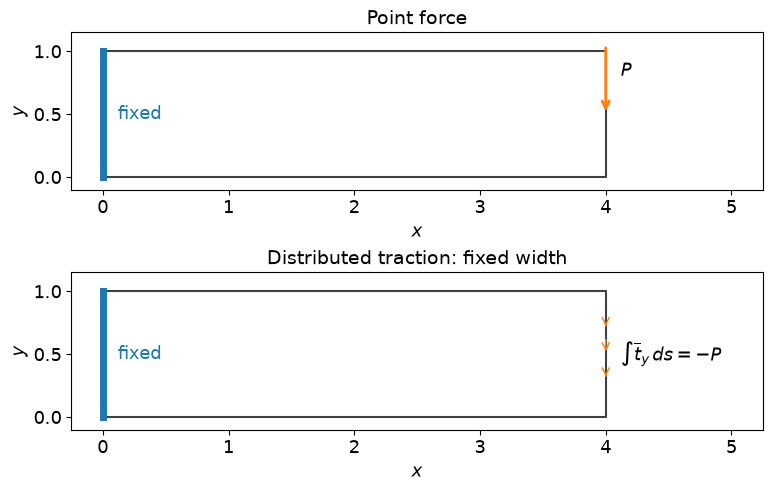

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4.8), layout="constrained")
for ax, title in zip(axes, ["Point force", "Distributed traction: fixed width"]):
    ax.plot([0, 4, 4, 0, 0], [0, 0, 1, 1, 0], color="0.25")
    ax.plot([0, 0], [0, 1], color="tab:blue", linewidth=5)
    ax.set(xlim=(-0.25, 5.25), ylim=(-0.1, 1.15),
           xlabel=r"$x$", ylabel=r"$y$", title=title, aspect="equal")
    ax.text(0.12, 0.5, "fixed", va="center", color="tab:blue")
axes[0].annotate("", xy=(4, 0.5), xytext=(4, 1.05),
                 arrowprops={"arrowstyle": "->", "color": "tab:orange", "lw": 2})
axes[0].text(4.12, 0.8, r"$P$")
for y in np.linspace(0.3, 0.7, 3):
    s = (y - 0.25) / 0.5
    axes[1].annotate("", xy=(4, y), xytext=(4, y + 0.14 * 4 * s * (1-s)),
                     arrowprops={"arrowstyle": "->", "color": "tab:orange"})
axes[1].text(4.12, 0.5, r"$\int\overline{t}_y\,ds=-P$", va="center")
plt.show()


## Variational forms and the finite element load vector

For plane stress,
$$
\boldsymbol{\varepsilon}(\boldsymbol{u})
=\tfrac12(\nabla\boldsymbol{u}+\nabla\boldsymbol{u}^{T}),\qquad
\boldsymbol{\sigma}(\boldsymbol{u})
=2\mu\boldsymbol{\varepsilon}(\boldsymbol{u})
+\lambda_{\mathrm{ps}}\operatorname{tr}(\boldsymbol{\varepsilon}(\boldsymbol{u}))\boldsymbol{I},
$$
where $\mu=E/[2(1+\nu)]$ and $\lambda_{\mathrm{ps}}=E\nu/(1-\nu^2)$. There is no body force, so $-\nabla\cdot\boldsymbol{\sigma}=\boldsymbol{0}$ in $\Omega$. The distributed-load case has zero traction on the upper and lower edges and on the unloaded part of the right edge. The point-load case has zero traction away from the force.
The discrete test and trial space consists of continuous vector-valued $P_1$ functions that vanish on $x=0$. The bilinear form is
$$
a_{\mathrm{el}}(\boldsymbol{u},\boldsymbol{v})
=\int_\Omega\boldsymbol{\sigma}(\boldsymbol{u}):
\boldsymbol{\varepsilon}(\boldsymbol{v})\,d\boldsymbol{x}.
$$

For the distributed load, set $s=(y-1/4)/w$ on the loaded segment $\Gamma_P$. Then
$$
\overline{\boldsymbol{t}}(y)
=\begin{bmatrix}0\\-6P\,s(1-s)/w\end{bmatrix},\qquad
\ell_{\mathrm{dist}}(\boldsymbol{v})
=\int_{\Gamma_P}\overline{\boldsymbol{t}}\cdot\boldsymbol{v}\,ds.
$$
The integral of its vertical component is $-6P\int_0^1s(1-s)\,ds=-P$.

For the point load, the **discrete** load functional is
$$
\ell_{\mathrm{point}}(\boldsymbol{v}_h)=-P\,v_{h,y}(\boldsymbol{x}_P).
$$
Since $\boldsymbol{x}_P$ is a node on every mesh, this means adding $-P$ to its vertical entry in the assembled load vector. It is not a traction spread over one mesh edge.

Point evaluation is defined for these continuous finite element functions, but it is not a bounded functional on the continuum $H^1$ space in two dimensions. Solving each finite element system therefore does not establish the existence of a finite-energy continuum solution for the ideal point force.


In [3]:
E = 1.0
nu = 0.3
P = 1.0e-6
width = 0.5
mu = E / (2 * (1 + nu))
lambda_ps = E * nu / (1 - nu**2)

def strain(u):
    return ufl.sym(ufl.grad(u))

def stress(u):
    return 2 * mu * strain(u) + lambda_ps * ufl.tr(strain(u)) * ufl.Identity(2)


## Assemble and solve

Use $4n$ subdivisions along the length and $n$ along the height. For the initial uniform mesh, $h=\sqrt{2}/n$. Subsequent local refinements give nested, nonuniform meshes.

DOLFINx stores this vector-valued $P_1$ space in blocks of two entries per node: horizontal, then vertical displacement. The code checks this layout before applying the point force. The PETSc lines assemble $\boldsymbol{K}$ and $\boldsymbol{F}$, impose zero displacement, and solve $\boldsymbol{K}\boldsymbol{U}=\boldsymbol{F}$ by direct LU factorization.

The function returns the solution and quantities needed for the comparison. Reactions use the original, unconstrained stiffness matrix.


In [4]:
def solve_cantilever(n, loading, domain=None, width=0.5):
    if domain is None:
        domain = mesh.create_rectangle(
            MPI.COMM_SELF, [np.array([0., 0.]), np.array([4., 1.])],
            [4*n, n], cell_type=mesh.CellType.triangle)
    V = fem.functionspace(domain, ("Lagrange", 1, (2,)))
    coordinates = V.tabulate_dof_coordinates()
    assert V.dofmap.index_map_bs == 2

    clamped_facets = mesh.locate_entities_boundary(
        domain, 1, lambda x: np.isclose(x[0], 0.0))
    clamped_dofs = fem.locate_dofs_topological(V, 1, clamped_facets)
    bc = fem.dirichletbc(np.zeros(2, dtype=PETSc.ScalarType), clamped_dofs, V)

    loaded_facets = mesh.locate_entities_boundary(
        domain, 1, lambda x: np.isclose(x[0], 4.0)
        & (x[1] >= 0.5-width/2 - 1e-10) & (x[1] <= 0.5+width/2 + 1e-10))
    tags = mesh.meshtags(domain, 1, loaded_facets,
                        np.ones(len(loaded_facets), dtype=np.int32))
    ds = ufl.Measure("ds", domain=domain, subdomain_data=tags,
                     metadata={"quadrature_degree": 4})
    x = ufl.SpatialCoordinate(domain)
    s = (x[1] - (0.5-width/2)) / width
    traction = ufl.as_vector((0., -6 * P / width * s * (1-s)))
    trial = ufl.TrialFunction(V)
    test = ufl.TestFunction(V)
    a = fem.form(ufl.inner(stress(trial), strain(test)) * ufl.dx)

    # This is also used to measure the same weighted end displacement in both cases.
    distributed_form = fem.form(ufl.dot(traction, test) * ds(1))
    F_distributed = petsc.assemble_vector(distributed_form)
    F_distributed.ghostUpdate(addv=PETSc.InsertMode.ADD, mode=PETSc.ScatterMode.REVERSE)
    F = F_distributed.copy()
    point_nodes = np.flatnonzero(np.isclose(coordinates[:, 0], 4.)
                                & np.isclose(coordinates[:, 1], 0.5))
    assert len(point_nodes) == 1
    point_node = point_nodes[0]
    if loading == "point":
        F.array[:] = 0
        F.array[2*point_node + 1] = -P
    elif loading != "distributed":
        raise ValueError("loading must be 'point' or 'distributed'")

    # Check resultant and moment of the assembled nodal forces before imposing BCs.
    nodal_forces = F.array.reshape(-1, 2)
    resultant = nodal_forces.sum(axis=0)
    moment = np.sum(coordinates[:, 0] * nodal_forces[:, 1]
                    - coordinates[:, 1] * nodal_forces[:, 0])
    K = petsc.assemble_matrix(a, bcs=[bc])
    K.assemble()
    petsc.set_bc(F, [bc])
    u_h = fem.Function(V)
    solver = PETSc.KSP().create(domain.comm)
    solver.setOperators(K)
    solver.setType("preonly")
    solver.getPC().setType("lu")
    solver.solve(F, u_h.x.petsc_vec)
    u_h.x.scatter_forward()
    assert solver.getConvergedReason() > 0

    compliance = F.dot(u_h.x.petsc_vec).real
    energy_squared = fem.assemble_scalar(fem.form(
        ufl.inner(stress(u_h), strain(u_h)) * ufl.dx)).real
    K_original = petsc.assemble_matrix(a)
    K_original.assemble()
    reactions = F.duplicate()
    K_original.mult(u_h.x.petsc_vec, reactions)
    reactions.axpy(-1, F)
    left_nodes = np.flatnonzero(np.isclose(coordinates[:, 0], 0.))
    reaction_y = reactions.array[2*left_nodes + 1].sum().real

    displacement = u_h.x.array.real.reshape(-1, 2)
    probe_nodes = np.flatnonzero(np.isclose(coordinates[:, 0], 3.)
                                & np.isclose(coordinates[:, 1], 0.5))
    assert len(probe_nodes) == 1
    midpoint_down = -displacement[point_node, 1]
    probe_down = -displacement[probe_nodes[0], 1]
    average_down = F_distributed.dot(u_h.x.petsc_vec).real / P

    # P1 displacement gives constant strain-energy density on each triangle.
    W = fem.functionspace(domain, ("DG", 0))
    density = fem.Function(W)
    density.interpolate(fem.Expression(
        0.5 * ufl.inner(stress(u_h), strain(u_h)), W.element.interpolation_points))
    count = domain.topology.index_map(2).size_local
    values = np.array([density.x.array[W.dofmap.cell_dofs(e)[0]].real
                       for e in range(count)])
    centers = mesh.compute_midpoints(domain, 2, np.arange(count, dtype=np.int32))
    near_load = np.linalg.norm(centers[:, :2] - [4., 0.5], axis=1) < 0.25
    peak_near_load = values[near_load].max()
    # W >= mu * (epsilon:epsilon) bounds the strain magnitude on these meshes.
    assert np.sqrt(values.max() / mu) < 0.05

    assert np.allclose(resultant, [0., -P], rtol=1e-10, atol=1e-12)
    assert np.isclose(moment, -4*P, rtol=1e-10)
    assert np.isclose(reaction_y, P, rtol=1e-7)
    assert np.isclose(compliance, energy_squared, rtol=1e-8)
    assert np.max(np.abs(displacement[left_nodes])) < 1e-12
    # The largest triangle edge gives h, including on nonuniform meshes.
    element_nodes = domain.geometry.x[domain.geometry.dofmap]
    h = 0.0
    for a, b in [(0, 1), (1, 2), (2, 0)]:
        h = max(h, np.linalg.norm(element_nodes[:, a] - element_nodes[:, b], axis=1).max())
    result = {
        "n": n, "h": h, "DOFs": len(u_h.x.array),
        "compliance/P^2": compliance/P**2,
        "midpoint displacement/P": midpoint_down/P,
        "weighted end displacement/P": average_down/P,
        "probe displacement/P": probe_down/P,
        "peak near-load density/P^2": peak_near_load/P**2,
        "reaction/P": reaction_y/P,
        "energy identity relative difference": abs(compliance-energy_squared)/energy_squared,
    }
    solver.destroy()
    K.destroy()
    K_original.destroy()
    F.destroy()
    F_distributed.destroy()
    reactions.destroy()
    return result, domain, u_h, values


## Estimator-driven refinement for distributed loading

For distributed widths $w=1/2$ and $w=1/4$, use the **elasticity residual indicators** to select elements. The separate prescribed-refinement point-force experiment appears after Task 2.

For constant material and $P_1$ displacement, the element stress is constant and the body force is zero. Thus $\boldsymbol r_e=\boldsymbol 0$. The remaining residuals are
$$
\boldsymbol j_{\mathcal F}
=-\bigl(\boldsymbol\sigma_h^+\boldsymbol n^+
       +\boldsymbol\sigma_h^-\boldsymbol n^-\bigr)
\quad\text{on interior facets},\qquad
\boldsymbol j_{\mathcal F}
=\overline{\boldsymbol t}-\boldsymbol\sigma_h\boldsymbol n
\quad\text{on Neumann facets}.
$$
Zero prescribed traction on the top, bottom, and unloaded end facets still gives a boundary residual $-\boldsymbol\sigma_h\boldsymbol n$; these facets must not be omitted. There is no Neumann residual on the clamped edge.

For $E=1$, use the Chapter 8 vector-residual indicator
$$
\eta_e^2=
\frac12\sum_{\substack{\mathcal F\subset\partial\mathcal K_e\\
                        \mathcal F\ {\rm interior}}}
h_{\mathcal F}\int_{\mathcal F}\boldsymbol j_{\mathcal F}\cdot\boldsymbol j_{\mathcal F}\,ds
+\sum_{\substack{\mathcal F\subset\partial\mathcal K_e\\
                 \mathcal F\ {\rm Neumann}}}
h_{\mathcal F}\int_{\mathcal F}\boldsymbol j_{\mathcal F}\cdot\boldsymbol j_{\mathcal F}\,ds.
$$
Here $h_{\mathcal F}$ is edge length. This indicator is not an exact energy error; the reliability constant is not computed. It is **not evaluated for the ideal point force**.

The DG0 assembly below allocates one entry per element, just as in the Gaussian notebook. No discontinuous Galerkin PDE method is being used.


In [5]:
def estimate_elasticity(domain, u_h, width):
    """Return squared interior and Neumann contributions in element order."""
    domain.topology.create_connectivity(1, 2)
    W = fem.functionspace(domain, ("DG", 0))
    z = ufl.TestFunction(W)
    normal = ufl.FacetNormal(domain)
    h_F = ufl.avg(ufl.FacetArea(domain))
    sigma_h = stress(u_h)

    # Both sides of an interior facet receive half of its squared contribution.
    jump = -ufl.jump(sigma_h, normal)
    interior_form = (
        0.5*h_F*ufl.dot(jump, jump)*z("+")*ufl.dS
        + 0.5*h_F*ufl.dot(jump, jump)*z("-")*ufl.dS
    )

    # Tag the loaded segment 1 and all other Neumann facets 2.
    exterior = mesh.exterior_facet_indices(domain.topology)
    clamped = mesh.locate_entities_boundary(
        domain, 1, lambda x: np.isclose(x[0], 0.))
    loaded = mesh.locate_entities_boundary(
        domain, 1, lambda x: np.isclose(x[0], 4.)
        & (x[1] >= 0.5-width/2-1e-10) & (x[1] <= 0.5+width/2+1e-10))
    neumann = np.setdiff1d(exterior, clamped)
    tags = np.full(len(neumann), 2, dtype=np.int32)
    tags[np.isin(neumann, loaded)] = 1
    facet_tags = mesh.meshtags(domain, 1, neumann, tags)
    ds = ufl.Measure("ds", domain=domain, subdomain_data=facet_tags,
                     metadata={"quadrature_degree": 4})
    x = ufl.SpatialCoordinate(domain)
    s = (x[1] - (0.5-width/2)) / width
    traction = ufl.as_vector((0., -6*P/width*s*(1-s)))
    j_loaded = traction - ufl.dot(sigma_h, normal)
    j_free = -ufl.dot(sigma_h, normal)
    boundary_form = (
        ufl.FacetArea(domain)*ufl.dot(j_loaded, j_loaded)*z*ds(1)
        + ufl.FacetArea(domain)*ufl.dot(j_free, j_free)*z*ds(2)
    )
    interior_vector = fem.assemble_vector(fem.form(interior_form))
    boundary_vector = fem.assemble_vector(fem.form(boundary_form))
    count = domain.topology.index_map(2).size_local
    interior_part = np.zeros(count)
    boundary_part = np.zeros(count)
    for e in range(count):
        dof = W.dofmap.cell_dofs(e)[0]
        interior_part[e] = interior_vector.array[dof].real
        boundary_part[e] = boundary_vector.array[dof].real
    return interior_part, boundary_part


In [6]:
def mark_elements(squared_indicators, theta=0.5):
    order = np.argsort(squared_indicators)[::-1]
    marked = []
    selected_sum = 0.
    target = theta * squared_indicators.sum()
    for e in order:
        marked.append(e)
        selected_sum += squared_indicators[e]
        if selected_sum >= target:
            break
    return np.array(marked, dtype=np.int32)

def refine_marked_elements(domain, marked):
    domain.topology.create_entities(1)
    domain.topology.create_connectivity(2, 1)
    edges = mesh.compute_incident_entities(domain.topology, marked, 2, 1)
    refined, _, _ = mesh.refine(domain, edges)
    return refined


### Plotting the selection

The three rows show the indicator values, marked elements, and actual mesh returned by refinement. The thick black edge is clamped; the orange segment carries the distributed load. Each figure has its own indicator color scale, so compare the numerical colorbar values across cycles. Large residuals need not occur only where the load is applied.


In [7]:
def plot_element_values(domain, values, title):
    cells, _, coordinates = plot.vtk_mesh(domain)
    triangles = mtri.Triangulation(
        coordinates[:, 0], coordinates[:, 1], cells.reshape(-1, 4)[:, 1:])
    fig, ax = plt.subplots(figsize=(11, 3), layout="constrained")
    image = ax.tripcolor(triangles, facecolors=values, cmap="magma", shading="flat")
    ax.triplot(triangles, color="0.3", linewidth=0.25)
    ax.set(title=title, xlabel=r"$x_1$", ylabel=r"$x_2$", aspect="equal")
    fig.colorbar(image, ax=ax, shrink=0.8)
    return fig

def draw_elastic_refinement(domain, squared_indicators, marked, refined, title, width=0.5):
    cells, _, coordinates = plot.vtk_mesh(domain)
    triangles = mtri.Triangulation(
        coordinates[:, 0], coordinates[:, 1], cells.reshape(-1, 4)[:, 1:])
    fig, panels = plt.subplots(3, 2, figsize=(8, 7.2), layout="constrained",
                                gridspec_kw={"width_ratios": [30, 1]})
    axes = panels[:, 0]
    image = axes[0].tripcolor(triangles, facecolors=np.sqrt(squared_indicators)/P,
                              cmap="magma", shading="flat")
    axes[0].triplot(triangles, color="0.3", linewidth=0.25, alpha=0.5)
    fig.colorbar(image, cax=panels[0, 1], label=r"$\eta_e/P$")
    for ax in panels[1:, 1]:
        ax.axis("off")
    selected = np.zeros(len(squared_indicators))
    selected[marked] = 1.
    axes[1].tripcolor(triangles, facecolors=selected, cmap="Blues", vmin=0, vmax=1.5)
    axes[1].triplot(triangles, color="0.3", linewidth=0.3)
    cells_new, _, coordinates_new = plot.vtk_mesh(refined)
    new_triangles = mtri.Triangulation(
        coordinates_new[:, 0], coordinates_new[:, 1], cells_new.reshape(-1, 4)[:, 1:])
    axes[2].triplot(new_triangles, color="0.3", linewidth=0.3)
    for ax, heading in zip(axes, ["Indicators on current mesh",
                                  f"Marked elements (blue): {len(marked)}",
                                  "Conforming mesh after refinement"]):
        ax.set(title=heading, xlabel=r"$x_1$", ylabel=r"$x_2$", aspect="equal",
               xlim=(0, 4), ylim=(0, 1))
    for ax in axes:
        ax.plot([0, 0], [0, 1], color="black", linewidth=3)
        ax.plot([4, 4], [0.5-width/2, 0.5+width/2], color="tab:orange", linewidth=3)
    fig.suptitle(title, fontsize=15)
    return fig


## Supplied first estimator-driven refinement

Use width $w=1/2$ and $32\times8$ rectangles split into triangles. Solve, compute the squared indicators, select at least half their total, and refine. The three-row figure distinguishes the **marked** elements from the mesh refinements needed for conformity.


/var/folders/tt/zt64sf2n4kgfkx71d8pf39440000gn/T/ipykernel_44732/892400102.py:100: DeprecationWarning: dofmap is deprecated. Use dofmaps[0] instead.
  element_nodes = domain.geometry.x[domain.geometry.dofmap]


Initial vector DOFs: 594
Marked fraction of eta^2: 0.5009665208740981


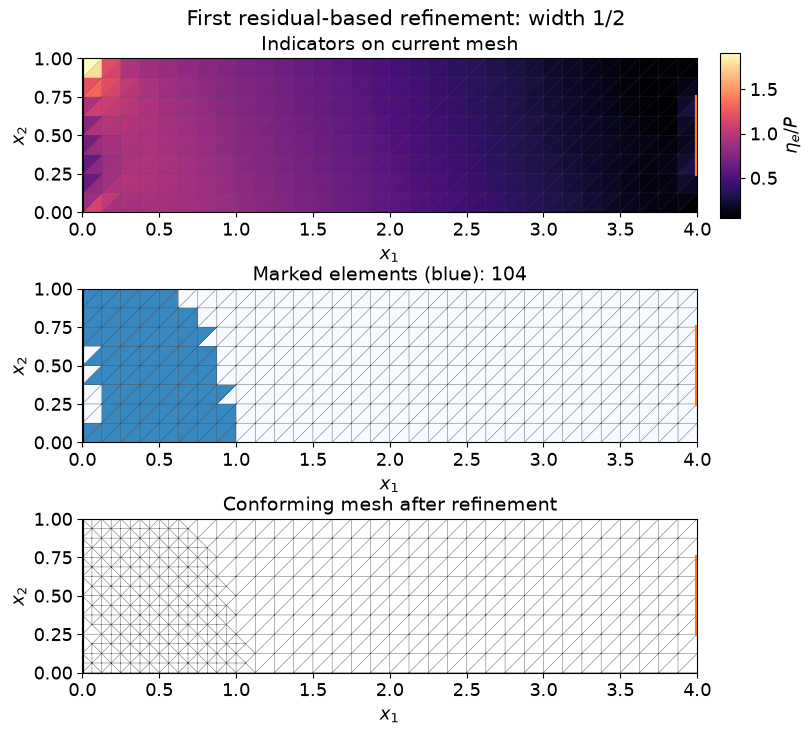

In [8]:
initial_domain = mesh.create_rectangle(
    MPI.COMM_SELF, [np.array([0., 0.]), np.array([4., 1.])], [32, 8],
    cell_type=mesh.CellType.triangle)
initial_result, _, u_initial, _ = solve_cantilever(
    8, "distributed", initial_domain, width=0.5)
interior_initial, boundary_initial = estimate_elasticity(initial_domain, u_initial, 0.5)
squared_initial = interior_initial + boundary_initial
marked_initial = mark_elements(squared_initial, 0.5)
refined_initial = refine_marked_elements(initial_domain, marked_initial)
print("Initial vector DOFs:", initial_result["DOFs"])
print("Marked fraction of eta^2:",
      squared_initial[marked_initial].sum()/squared_initial.sum())
draw_elastic_refinement(initial_domain, squared_initial, marked_initial, refined_initial,
                       "First residual-based refinement: width 1/2")
plt.show()


## Task 1. Check the Neumann residual (10 marks)

Use the supplied initial solution for $w=1/2$.

1. Print $\eta_{\mathrm{int}}/P$, $\eta_N/P$, and $\eta/P$, where
   $\eta_{\mathrm{int}}^2$ and $\eta_N^2$ are the sums of `interior_initial` and `boundary_initial`. Check that $\eta^2=\eta_{\mathrm{int}}^2+\eta_N^2$.
2. Plot $\sqrt{\eta_{e,N}^2}/P$ on the initial mesh, using `boundary_initial` as the elementwise squared values. Call `plot_element_values(initial_domain, np.sqrt(boundary_initial)/P, title)`, with a suitable title. Include the whole cantilever, not only the loaded end.
3. Explain why zero prescribed traction on an unloaded boundary does **not** imply that its residual is zero. State the residual on that boundary.

The volume term is zero for this constant-material, zero-body-force $P_1$ problem. Do not replace the omitted boundary terms by a volume term.


In [9]:
# Compute the residual contributions and draw the boundary-contribution map here.


## Task 2. Let the estimator select the mesh (20 marks)

Use $w=1/2$ and $w=1/4$, with a **new initial $32\times8$ subdivision** for each width. Keep each width fixed during its run.

Write the adaptive loop for seven solves, numbered 0 through 6, and six refinements. After each solve, compute the residual indicators. Except after the last solve, use bulk marking with $\theta=0.5$ and check that the selected squared fraction is at least $0.5$. Do not impose a refinement radius around the load.

Here $C_m=\ell(\boldsymbol u_m)=a_{\mathrm{el}}(\boldsymbol u_m,\boldsymbol u_m)$ is compliance. Vector DOFs count both displacement components, including prescribed values. The exact solution is unknown; do not label $\eta$ or differences of compliance as a true error.

Submit:

1. One table per width containing cycle, vector DOFs, $\eta/P$, $C_m/P^2$, and $-u_{m,2}(3,1/2)/P$. For cycles 0–5, also record the number of marked elements and their selected fraction of $\eta^2$.
2. For **cycles 0, 2, and 4 of each run**, call `draw_elastic_refinement(current_mesh, eta_squared, marked, refined_mesh, title, width=load_width)` before replacing the current mesh. Submit the six figures showing indicators, marked elements, and resulting meshes.
3. Plot $\eta/P$ against vector DOFs for the two widths on one set of log-log axes. Plot $C_m/P^2$ against DOFs separately.
4. From the marked-element plots, identify whether selection is restricted to the loaded end or also occurs elsewhere. Explain the observed locations using stress jumps and Neumann mismatch.



In [10]:
# Write the two residual-based adaptive runs here.


## Supplied comparison: prescribed refinement around a point force

This next calculation is **not the adaptive algorithm above**. It uses the same prescribed mesh sequence for a point force and a distributed force of width $1/2$. Start with $64\times16$ rectangles split into triangles. At step $m$, refine triangles whose centers lie within radius $0.3\,2^{-m}$ of $(4,1/2)$. Most of the mesh stays fixed. The mesh panels at steps 0, 3, and 6 apply to **both** loading cases; the orange marker locates the load center.

This controlled comparison separates the response to the load idealization from the residual-based element-selection exercise. It supplies the data for Task 3.


## Does the sequence settle in energy?

For nested spaces, with the **same** load functional on both meshes, Galerkin orthogonality and symmetry give
$$
a_{\mathrm{el}}(\boldsymbol{u}_{m+1},\boldsymbol{u}_m)
=\ell(\boldsymbol{u}_m)
=a_{\mathrm{el}}(\boldsymbol{u}_m,\boldsymbol{u}_m)=C_m.
$$
Expanding the square therefore gives
$$
\|\boldsymbol{u}_{m+1}-\boldsymbol{u}_m\|_{a_{\mathrm{el}}}^2
=C_{m+1}-C_m.
$$
This identity uses only the discrete equations. It holds for both load vectors here; it does **not** assert the existence of a finite-energy continuum solution for the point force.

We plot this successive-mesh difference, not a true error. A sequence converging in energy must have these differences tend to zero. The converse does not follow from this check alone. For example, increments that merely become small need not establish convergence.


/var/folders/tt/zt64sf2n4kgfkx71d8pf39440000gn/T/ipykernel_44732/892400102.py:100: DeprecationWarning: dofmap is deprecated. Use dofmaps[0] instead.
  element_nodes = domain.geometry.x[domain.geometry.dofmap]


,cycle,DOFs,point C/P^2,distributed C/P^2,point energy difference/P,distributed energy difference/P
0,0,2210,264.482765,263.599760,NaN,NaN
1,1,2476,264.945060,263.623443,0.679923,0.153893
2,2,2738,265.380093,263.626096,0.659570,0.051510
3,3,3000,265.816256,263.626276,0.660427,0.013422
4,4,3262,266.252657,263.626289,0.660606,0.003619
5,5,3524,266.689108,263.626290,0.660644,0.000969
6,6,3786,267.125569,263.626290,0.660652,0.000247


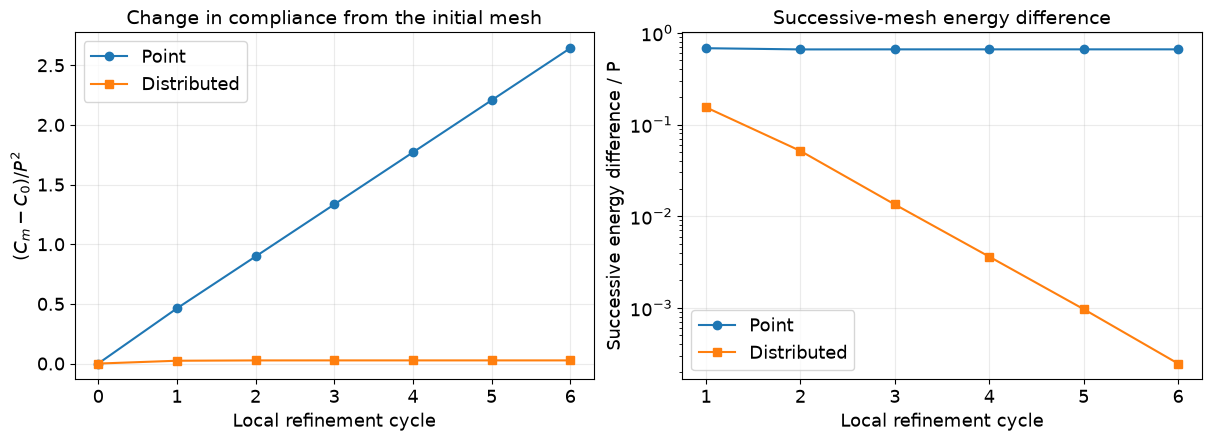

In [11]:
local_domain = mesh.create_rectangle(
    MPI.COMM_SELF, [np.array([0., 0.]), np.array([4., 1.])],
    [64, 16], cell_type=mesh.CellType.triangle)
local_point = []
local_distributed = []
local_dofs = []
local_meshes = []

for cycle in range(7):
    rp, _, _, _ = solve_cantilever(16, "point", local_domain)
    rd, _, _, _ = solve_cantilever(16, "distributed", local_domain)
    local_point.append(rp["compliance/P^2"])
    local_distributed.append(rd["compliance/P^2"])
    local_dofs.append(rp["DOFs"])
    local_meshes.append(local_domain)
    if cycle < 6:
        count = local_domain.topology.index_map(2).size_local
        elements = np.arange(count, dtype=np.int32)
        centers = mesh.compute_midpoints(local_domain, 2, elements)
        distance = np.linalg.norm(centers[:, :2] - [4., 0.5], axis=1)
        marked = elements[distance < 0.3 * 0.5**cycle]
        assert len(marked) > 0
        local_domain.topology.create_entities(1)
        local_domain.topology.create_connectivity(2, 1)
        edges = mesh.compute_incident_entities(local_domain.topology, marked, 2, 1)
        local_domain, _, _ = mesh.refine(local_domain, edges)

point_increments = np.diff(local_point)
distributed_increments = np.diff(local_distributed)
assert np.all(point_increments > 0)
assert np.all(distributed_increments > 0)
display(pd.DataFrame({
    "cycle": range(7), "DOFs": local_dofs,
    "point C/P^2": local_point,
    "distributed C/P^2": local_distributed,
    "point energy difference/P": [np.nan] + list(np.sqrt(point_increments)),
    "distributed energy difference/P": [np.nan] + list(np.sqrt(distributed_increments)),
}).round(6))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
axes[0].plot(range(7), np.array(local_point) - local_point[0], "o-", label="Point")
axes[0].plot(range(7), np.array(local_distributed) - local_distributed[0], "s-", label="Distributed")
axes[0].set(xlabel="Local refinement cycle", ylabel=r"$(C_m-C_0)/P^2$",
            title="Change in compliance from the initial mesh")
axes[1].semilogy(range(1, 7), np.sqrt(point_increments), "o-", label="Point")
axes[1].semilogy(range(1, 7), np.sqrt(distributed_increments),
                 "s-", label="Distributed")
axes[1].set(xlabel="Local refinement cycle", ylabel="Successive energy difference / P",
            title="Successive-mesh energy difference")
for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.25)
plt.show()


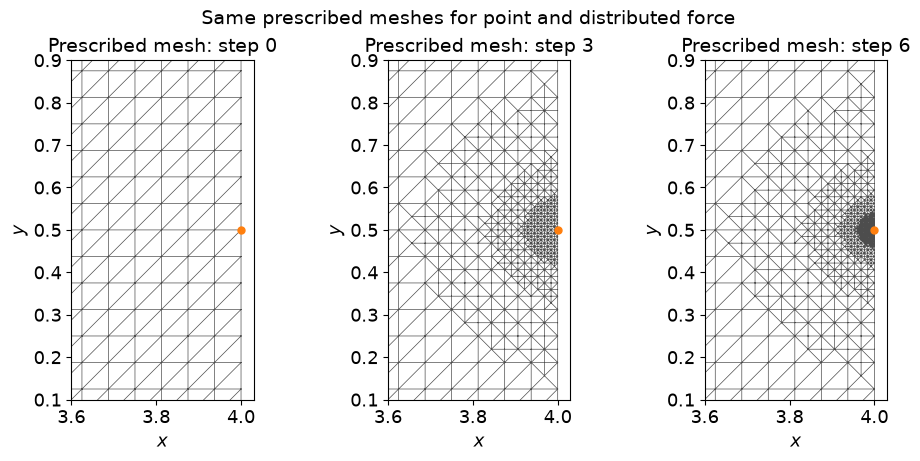

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(9.5, 4.5), layout="constrained")
for ax, cycle in zip(axes, [0, 3, 6]):
    cells, _, coordinates = plot.vtk_mesh(local_meshes[cycle])
    triangles = mtri.Triangulation(coordinates[:, 0], coordinates[:, 1],
                                  cells.reshape(-1, 4)[:, 1:])
    ax.triplot(triangles, color="0.3", linewidth=0.5)
    ax.plot(4., 0.5, "o", color="tab:orange", markersize=5)
    ax.set(xlim=(3.6, 4.03), ylim=(0.1, 0.9), aspect="equal",
           xlabel=r"$x$", ylabel=r"$y$", title=f"Prescribed mesh: step {cycle}")
fig.suptitle("Same prescribed meshes for point and distributed force", fontsize=14)
plt.show()


## Task 3. Distinguish refinement error from the loading model (10 marks)

Using the supplied **prescribed-refinement** comparison:

1. Make a compact table of the last three successive energy differences for the point force and width-$1/2$ distributed force, divided by $P$. State which sequence has become less sensitive to further local refinement and which has not. These are differences between two FE solutions, not known errors.
2. Explain why the residual formula used in Tasks 1–2 cannot simply be applied to an ideal point force as though it were an $L^2$ boundary traction.
3. Suppose the distributed width were reduced in proportion to the smallest element size after every refinement. Would that sequence still solve one fixed boundary-value problem? Explain why this matters when interpreting a convergence plot.

Keep the answer to one short paragraph after the table. No new continuum singularity proof is requested.


In [13]:
# Print the comparison table here.


Write your interpretation here.
